# Tema : Modelo Prophet

![](src/img/logo_utb.png)
![](src/img/logo_etd.png)
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

# Ejercicio 1. Demanda diaria de electricidad en Victoria, Australia

- Una aplicación común de estos modelos es el pronóstico de la demanda de electricidad. Tenemos la demanda de electricidad cada media hora (MWh) en Victoria, Australia, durante el periodo 2012-2014, junto con la temperatura (en grados Celsius) en Melbourne, la ciudad más grande de Victoria.
- Para este ejercicio agregamos los datos a frecuencia diaria. La demanda diaria es la suma de las demandas de cada media hora, expresada en GWh, y la temperatura diaria es la temperatura máxima del día.
- El objetivo es pronosticar la demanda de los últimos 90 días de 2014 y comparar varios modelos Prophet con un modelo de referencia. El notebook de LSTM usa exactamente los mismos datos y el mismo periodo de prueba, de modo que los resultados de ambos notebooks se pueden comparar.

In [1]:
# Ocultar los mensajes informativos de Prophet y Stan
import logging
logging.getLogger("prophet.plot").disabled = True
logging.getLogger("cmdstanpy").disabled = True

# Librerias necesarias

# Datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modelos Prophet
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

import itertools
import warnings
warnings.filterwarnings('ignore')

## Datos

In [2]:
# datos de electricidad
github_data = "https://raw.githubusercontent.com/fersalme/regresion-lineal-series-tiempo/refs/heads/main/data/vic_elec.csv"
vic_elec = pd.read_csv(github_data, parse_dates=["ds"])

vic_elec_df = (
    vic_elec
    .pivot(index=["ds", "Holiday"], columns="unique_id", values="y")
    .reset_index().rename_axis(None, axis="columns")
    .assign(ds=lambda x: pd.to_datetime(x["ds"]).dt.normalize())
    .groupby(["ds", "Holiday"])
    .agg({
        "Demand": "sum",          # Demanda total del día
        "Temperature": "max"      # Temperatura máxima del día
    })
    .reset_index()
    .assign(
        Demand=lambda x: x["Demand"] / 1e3,                     # MWh a GWh
        Working_Day=lambda x: (~x["Holiday"] & ~x["ds"].dt.dayofweek.isin([5, 6])).astype(int),
        Temperature2=lambda x: x["Temperature"] ** 2            # Término cuadrático de la temperatura
    )
)

print(f"Número de días: {len(vic_elec_df)}")
vic_elec_df.head()

Número de días: 1096


,ds,Holiday,Demand,Temperature,Working_Day,Temperature2
0,2012-01-01,True,222.437912,32.7,0,1069.29
1,2012-01-02,True,257.964724,39.6,0,1568.16
2,2012-01-03,False,267.098605,31.8,1,1011.24
3,2012-01-04,False,222.742287,25.1,1,630.01
4,2012-01-05,False,210.585240,21.2,1,449.44


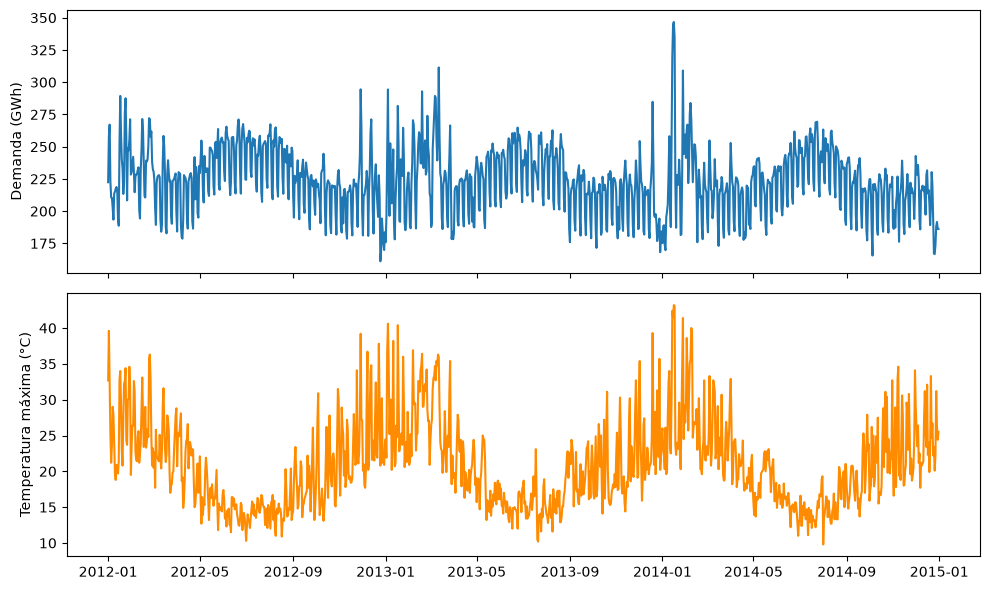

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(vic_elec_df["ds"], vic_elec_df["Demand"])
axes[0].set_ylabel("Demanda (GWh)")
axes[1].plot(vic_elec_df["ds"], vic_elec_df["Temperature"], color="darkorange")
axes[1].set_ylabel("Temperatura máxima (°C)")
plt.tight_layout()
plt.show()

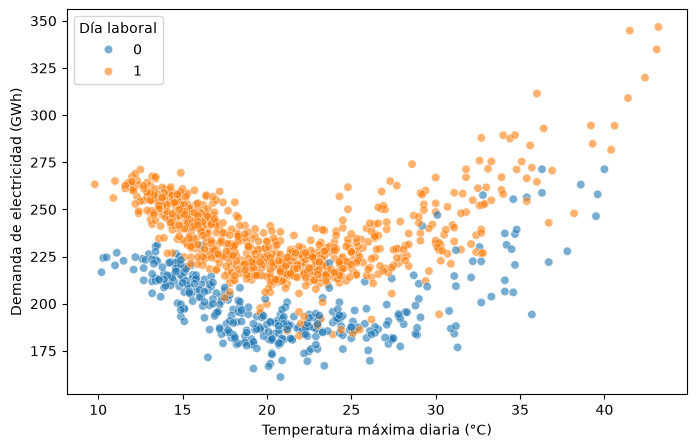

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=vic_elec_df, x="Temperature", y="Demand",
    hue="Working_Day", palette="tab10", alpha=0.6, ax=ax)
ax.set(
    xlabel="Temperatura máxima diaria (°C)",
    ylabel="Demanda de electricidad (GWh)",
)
ax.legend(title="Día laboral")
plt.show()

Si se representa la demanda de electricidad en función de la temperatura, se observa una relación no lineal entre ambas. La demanda aumenta con las temperaturas bajas, por el uso de calefacción, y con las temperaturas altas, por el uso de aire acondicionado. Esta forma de U se puede capturar incluyendo la temperatura y la temperatura al cuadrado como regresoras. Además, los días laborales tienen una demanda mayor que los fines de semana y festivos.

## Conjuntos de entrenamiento y prueba

- Prophet requiere un dataframe con la columna `ds` para las fechas y la columna `y` para la serie.
- Reservamos los últimos 90 días como conjunto de prueba. Ningún modelo usa esos datos durante la estimación, y con ellos medimos el error de pronóstico.

In [5]:
h = 90   # horizonte de pronóstico en días

datos = vic_elec_df.rename(columns={"Demand": "y"})
train = datos.iloc[:-h].copy()
test  = datos.iloc[-h:].copy()

print(f"Entrenamiento: {train['ds'].min().date()} a {train['ds'].max().date()} ({len(train)} días)")
print(f"Prueba:        {test['ds'].min().date()} a {test['ds'].max().date()} ({len(test)} días)")

Entrenamiento: 2012-01-01 a 2014-10-02 (1006 días)
Prueba:        2014-10-03 a 2014-12-31 (90 días)


In [6]:
# Métricas de error de pronóstico
def metricas(y_real, y_pred):
    error = np.asarray(y_real) - np.asarray(y_pred)
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE (%)": 100 * np.mean(np.abs(error / np.asarray(y_real))),
    }

resultados = {}
pronosticos_test = {}

## Modelo de referencia

- Un modelo complejo solo se justifica si pronostica mejor que un modelo simple. Usamos como referencia el **ingenuo estacional**, que pronostica cada día con el valor observado el mismo día de la semana anterior. Para un horizonte de 90 días, el modelo repite la última semana observada.

In [7]:
ultima_semana = train["y"].values[-7:]
pronostico_snaive = np.tile(ultima_semana, int(np.ceil(h / 7)))[:h]

pronosticos_test["Ingenuo estacional"] = pronostico_snaive
resultados["Ingenuo estacional"] = metricas(test["y"], pronostico_snaive)
pd.DataFrame(resultados).T.round(3)

,MAE,RMSE,MAPE (%)
Ingenuo estacional,10.776,15.196,5.343


## Modelo Prophet 1 con tendencia, estacionalidad y festivos

- El primer modelo solo usa la historia de la demanda. Prophet estima la tendencia, la estacionalidad anual y semanal, y el efecto de los festivos.
- Los festivos se construyen a partir de la columna `Holiday` de los datos. Prophet necesita un dataframe con las columnas `holiday` (nombre del evento) y `ds` (fecha).

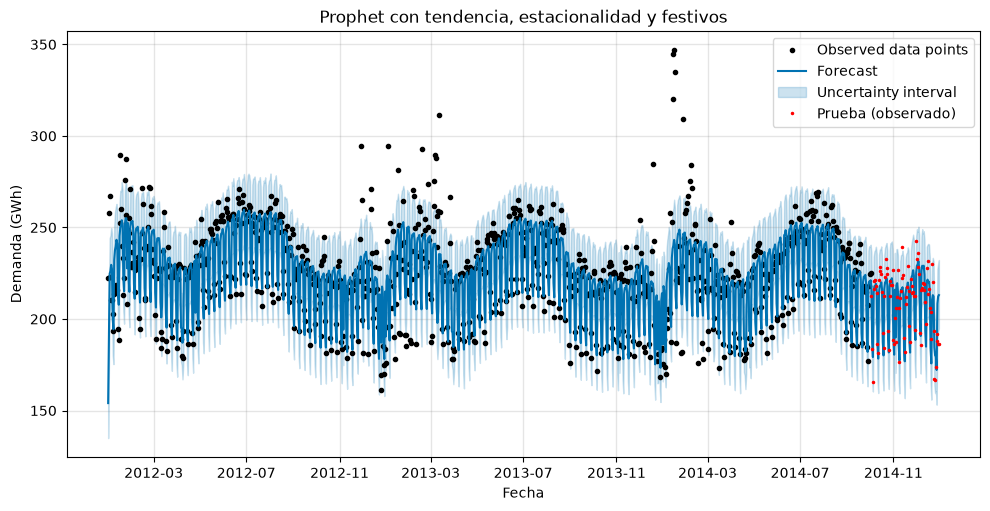

In [8]:
festivos = pd.DataFrame({
    "holiday": "festivo",
    "ds": datos.loc[datos["Holiday"], "ds"],
})

# Definir y ajustar el modelo
modelo_1 = Prophet(holidays=festivos)
modelo_1.fit(train[["ds", "y"]])

# Pronosticar los 90 días del conjunto de prueba
futuro_1 = modelo_1.make_future_dataframe(periods=h)
pronostico_1 = modelo_1.predict(futuro_1)

fig = modelo_1.plot(pronostico_1, figsize=(10, 5))
ax = fig.gca()
ax.plot(test["ds"], test["y"], ".", color="red", markersize=3, label="Prueba (observado)")
ax.set(xlabel="Fecha", ylabel="Demanda (GWh)", title="Prophet con tendencia, estacionalidad y festivos")
ax.legend()
plt.show()

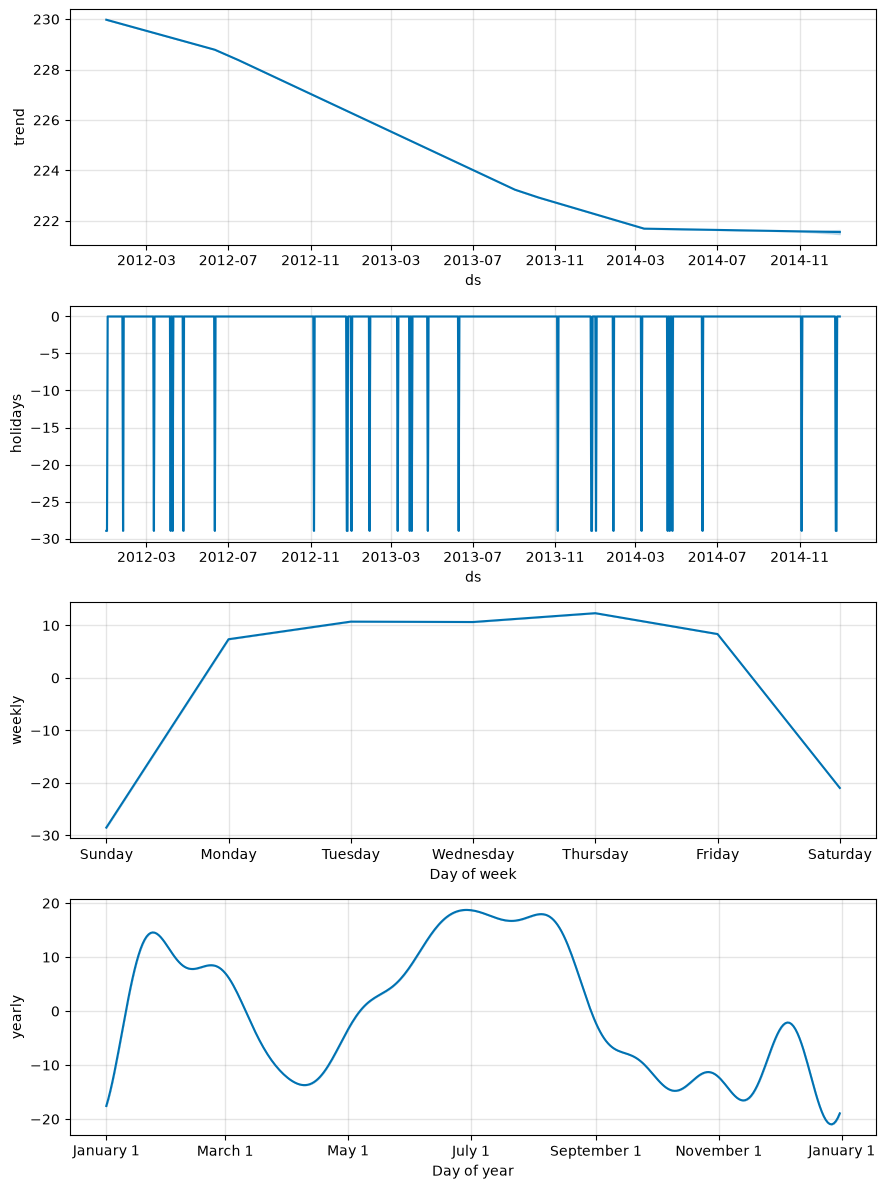

In [9]:
fig = modelo_1.plot_components(pronostico_1)

**Interpretación de los componentes**

- La tendencia muestra cómo cambia el nivel de la demanda en el periodo, una vez descontados los efectos estacionales.
- El componente de festivos muestra cuánto se reduce la demanda en un día festivo frente a un día normal.
- La estacionalidad semanal muestra una demanda más baja los sábados y domingos.
- La estacionalidad anual muestra una demanda más alta en el invierno austral (junio a agosto), por la calefacción, un pico en el verano (febrero), por el aire acondicionado, y una caída en las vacaciones de fin de año.

In [10]:
pronosticos_test["Prophet"] = pronostico_1["yhat"].values[-h:]
resultados["Prophet"] = metricas(test["y"], pronostico_1["yhat"].values[-h:])
pd.DataFrame(resultados).T.round(3)

,MAE,RMSE,MAPE (%)
Ingenuo estacional,10.776,15.196,5.343
Prophet,8.032,10.343,3.902


## Modelo Prophet 2 con regresoras

- El segundo modelo agrega tres regresoras con `add_regressor()`, que son la temperatura, la temperatura al cuadrado y el indicador de día laboral. El indicador de día laboral ya incluye los festivos, por lo que no se agregan por separado.
- Para pronosticar con regresoras, el dataframe futuro debe contener los valores de cada regresora en las fechas que se pronostican. Aquí usamos la temperatura observada en el periodo de prueba, lo que se conoce como **pronóstico ex post**. En la práctica la temperatura futura no se conoce y habría que usar el pronóstico del clima, por lo que el error real sería algo mayor.

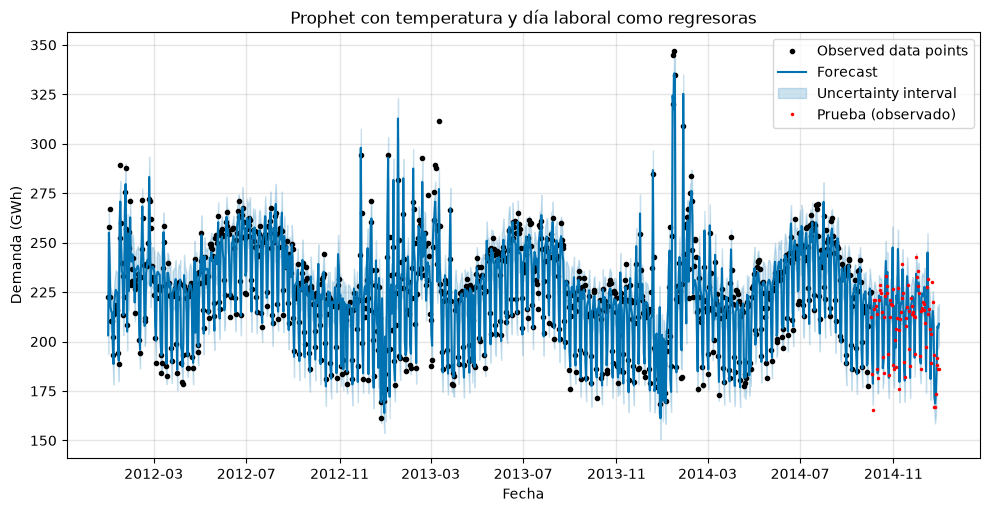

In [11]:
regresoras = ["Temperature", "Temperature2", "Working_Day"]

# Construir el modelo
modelo_2 = Prophet()
for regresora in regresoras:
    modelo_2.add_regressor(regresora)

# Estimar el modelo
modelo_2.fit(train[["ds", "y"] + regresoras])

# El futuro debe incluir los valores de las regresoras
futuro_2 = datos[["ds"] + regresoras]
pronostico_2 = modelo_2.predict(futuro_2)

fig = modelo_2.plot(pronostico_2, figsize=(10, 5))
ax = fig.gca()
ax.plot(test["ds"], test["y"], ".", color="red", markersize=3, label="Prueba (observado)")
ax.set(xlabel="Fecha", ylabel="Demanda (GWh)", title="Prophet con temperatura y día laboral como regresoras")
ax.legend()
plt.show()

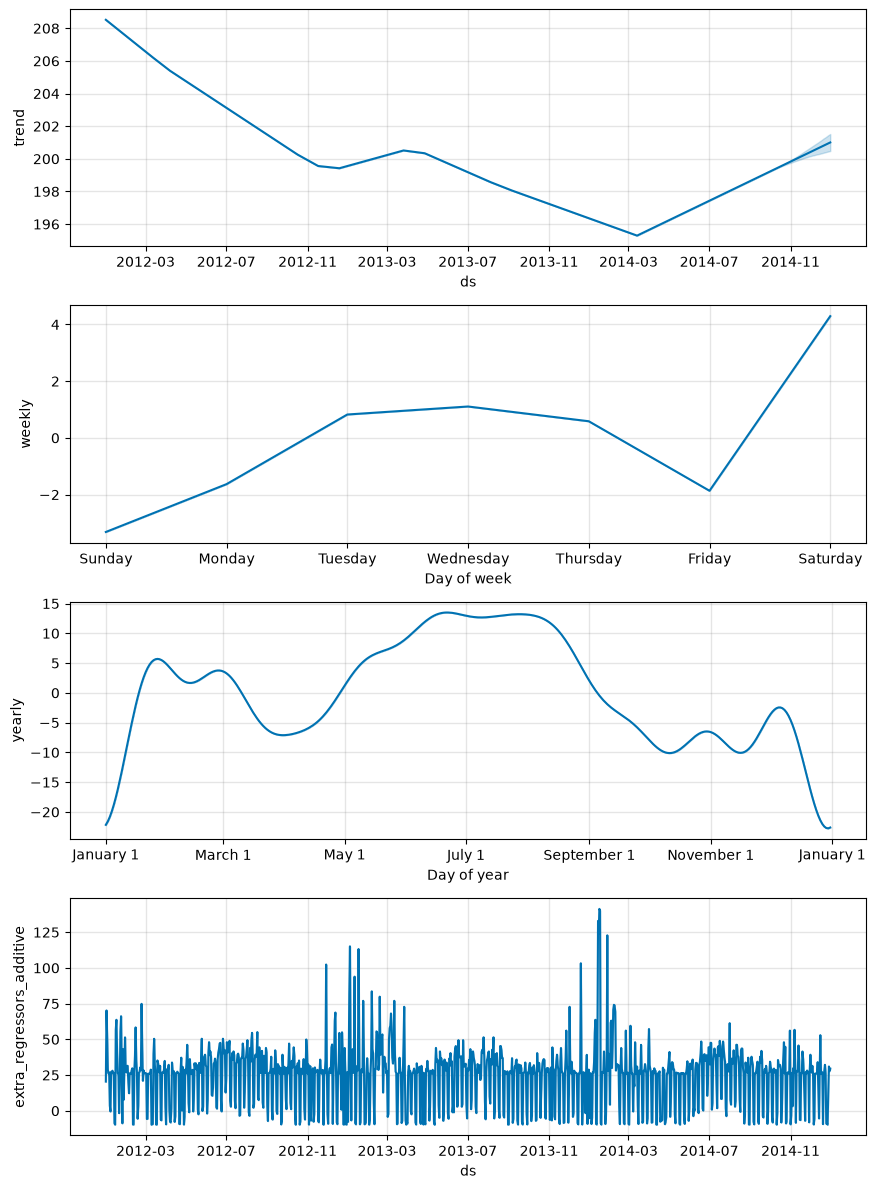

In [12]:
fig = modelo_2.plot_components(pronostico_2)

**Interpretación de los componentes**

- El componente `extra_regressors_additive` reúne el efecto de la temperatura y del día laboral. Sus valores más altos aparecen en las olas de calor del verano, como la de enero de 2014.
- La estacionalidad semanal casi desaparece. En el modelo 1 la diferencia entre un día laboral y un domingo era de unos 40 GWh, y ahora es de unos 8 GWh, porque el indicador de día laboral ya captura esa diferencia.
- La estacionalidad anual conserva una forma parecida a la del modelo 1, porque la temperatura máxima no explica todo el patrón del año. Por ejemplo, la caída de la demanda en las vacaciones de fin de año sigue apareciendo en este componente.

In [13]:
pronosticos_test["Prophet + regresoras"] = pronostico_2["yhat"].values[-h:]
resultados["Prophet + regresoras"] = metricas(test["y"], pronostico_2["yhat"].values[-h:])
pd.DataFrame(resultados).T.round(3)

,MAE,RMSE,MAPE (%)
Ingenuo estacional,10.776,15.196,5.343
Prophet,8.032,10.343,3.902
Prophet + regresoras,6.293,8.430,3.041


## Validación cruzada

- Una sola partición de entrenamiento y prueba depende de qué días quedaron en la prueba. La validación cruzada repite la evaluación en varias fechas de corte dentro del conjunto de entrenamiento.
- La serie de entrenamiento tiene 1,006 días. Usamos un entrenamiento inicial de 730 días, para que el modelo vea dos ciclos anuales completos, un horizonte de 90 días y un periodo de 90 días entre cortes. Con estos valores se obtienen tres cortes. Si usáramos un horizonte de 365 días, solo cabría un corte y la validación no sería confiable.
- La función `cross_validation()` vuelve a estimar el modelo en cada corte con los datos disponibles hasta ese momento. Para el modelo con regresoras usa los valores observados de las regresoras.

In [14]:
df_cv = cross_validation(
    model=modelo_2,
    initial="730 days",   # Tamaño del conjunto inicial de entrenamiento
    period="90 days",     # Distancia entre las fechas de corte
    horizon="90 days",    # Horizonte de pronóstico a evaluar
    parallel=None,
    disable_tqdm=True
)

print("Fechas de corte:", df_cv["cutoff"].dt.date.unique())

# Métricas por horizonte de pronóstico
df_p = performance_metrics(df_cv)
df_p[["horizon", "mae", "rmse", "mape"]].head(10)

Fechas de corte: [datetime.date(2014, 1, 5) datetime.date(2014, 4, 5)
 datetime.date(2014, 7, 4)]


,horizon,mae,rmse,mape
0,9 days,8.606189,10.937303,0.038828
1,10 days,9.600517,12.775458,0.040579
2,11 days,10.323070,13.452230,0.042218
3,12 days,10.388778,13.485917,0.041802
4,13 days,11.510046,14.946523,0.046878
5,14 days,11.336133,14.830149,0.046763
6,15 days,10.322164,13.837386,0.042181
7,16 days,9.733256,13.516007,0.039114
8,17 days,9.280928,12.797660,0.037148
9,18 days,9.236786,12.738590,0.036449


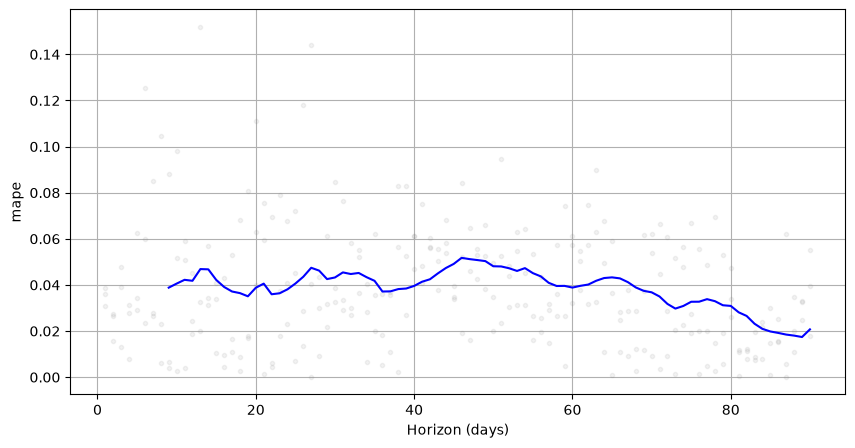

In [15]:
fig = plot_cross_validation_metric(df_cv, metric="mape", figsize=(10, 5))
plt.show()

- Cada punto gris es el error porcentual absoluto de un pronóstico, y la línea azul es el MAPE promedio según el número de días hacia adelante. El error crece poco con el horizonte porque el modelo usa la temperatura observada en cada día pronosticado.

## Ajuste de hiperparámetros

- Usamos la validación cruzada para elegir `changepoint_prior_scale`, que controla la flexibilidad de la tendencia, y `seasonality_prior_scale`, que controla la flexibilidad de la estacionalidad.
- Para cada combinación se estima el modelo en los tres cortes y se calcula el RMSE promedio. Se elige la combinación con menor RMSE.

In [16]:
grilla = {
    "changepoint_prior_scale": [0.01, 0.05, 0.5],
    "seasonality_prior_scale": [0.1, 10.0],
}
combinaciones = [dict(zip(grilla.keys(), v)) for v in itertools.product(*grilla.values())]

def crear_modelo(**parametros):
    modelo = Prophet(**parametros)
    for regresora in regresoras:
        modelo.add_regressor(regresora)
    return modelo

rmse_cv = []
for parametros in combinaciones:
    modelo = crear_modelo(**parametros).fit(train[["ds", "y"] + regresoras])
    cv = cross_validation(modelo, initial="730 days", period="90 days", horizon="90 days",
                          parallel=None, disable_tqdm=True)
    rmse_cv.append(performance_metrics(cv, rolling_window=1)["rmse"].values[0])

tabla_grilla = pd.DataFrame(combinaciones).assign(rmse_cv=rmse_cv).sort_values("rmse_cv")
tabla_grilla

,changepoint_prior_scale,seasonality_prior_scale,rmse_cv
0,0.01,0.1,9.758766
1,0.01,10.0,9.794005
2,0.05,0.1,10.533492
3,0.05,10.0,10.646076
4,0.50,0.1,13.053370
5,0.50,10.0,13.447172


In [17]:
# Reestimar el mejor modelo con todo el conjunto de entrenamiento
mejores_parametros = tabla_grilla.iloc[0][list(grilla.keys())].to_dict()
print("Mejores hiperparámetros:", mejores_parametros)

modelo_3 = crear_modelo(**mejores_parametros).fit(train[["ds", "y"] + regresoras])
pronostico_3 = modelo_3.predict(futuro_2)

pronosticos_test["Prophet + regresoras ajustado"] = pronostico_3["yhat"].values[-h:]
resultados["Prophet + regresoras ajustado"] = metricas(test["y"], pronostico_3["yhat"].values[-h:])

Mejores hiperparámetros: {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 0.1}


## Comparación de modelos en el conjunto de prueba

In [18]:
tabla_resultados = pd.DataFrame(resultados).T.sort_values("RMSE").round(3)
tabla_resultados

,MAE,RMSE,MAPE (%)
Prophet + regresoras ajustado,6.144,7.962,2.956
Prophet + regresoras,6.293,8.430,3.041
Prophet,8.032,10.343,3.902
Ingenuo estacional,10.776,15.196,5.343


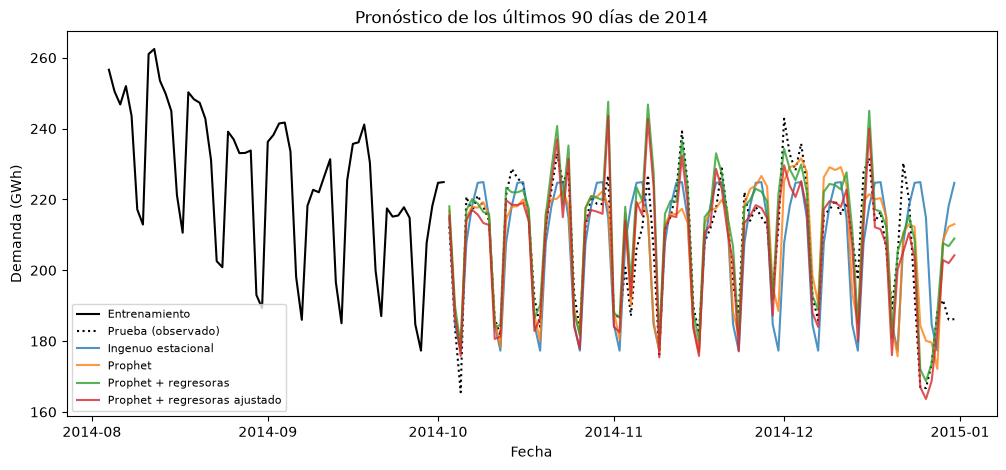

In [19]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train["ds"].iloc[-60:], train["y"].iloc[-60:], color="black", label="Entrenamiento")
ax.plot(test["ds"], test["y"], color="black", linestyle=":", label="Prueba (observado)")
for nombre, pronostico in pronosticos_test.items():
    ax.plot(test["ds"], pronostico, label=nombre, alpha=0.8)
ax.set(xlabel="Fecha", ylabel="Demanda (GWh)", title="Pronóstico de los últimos 90 días de 2014")
ax.legend(fontsize=8)
plt.show()

## Conclusiones

- Los tres modelos Prophet pronostican mejor que el ingenuo estacional. El modelo con regresoras y con los hiperparámetros ajustados reduce el RMSE de 15.2 a 8.0 GWh y el MAPE de 5.3% a 3.0%.
- La mayor mejora viene de agregar la temperatura y el día laboral. Esto coincide con el gráfico de dispersión, que muestra que la demanda depende de la temperatura de forma no lineal y que es mayor en los días laborales.
- El ajuste de hiperparámetros eligió un `changepoint_prior_scale` pequeño, es decir, una tendencia más rígida. Con solo tres años de datos, una tendencia flexible sigue cambios que no se mantienen en el futuro. La mejora frente a los valores por defecto es pequeña.
- El modelo con regresoras usó la temperatura observada en el periodo de prueba. En un pronóstico real se usaría el pronóstico del clima, por lo que el error sería mayor que el reportado aquí.
- Los resultados de esta tabla se pueden comparar con los del notebook de LSTM, que usa los mismos datos y el mismo periodo de prueba.